# Una U-Net de difusión con caras de anime

En los cuadernos 10 y 11 la red era un perceptrón y los datos eran juguetes. Aquí pasamos a imágenes reales: una muestra de 12 000 caras del dataset `huggan/anime-faces` de Hugging Face, reducidas a $32\times 32$ píxeles a color.

Cambian dos cosas:

1. **La red es una U-Net**, la arquitectura estándar de los modelos de difusión de imágenes.
2. **Las imágenes llevan etiqueta.** Agrupamos las caras por color de cabello y le pasamos ese grupo a la red. Así, al generar, podemos pedir "una cara de cabello oscuro" o "una de cabello rojizo".

Este cuaderno necesita GPU: corre en el contenedor `lab-pytorch` del servidor GPU. El entrenamiento tarda unos minutos.

In [1]:
import sys
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image


def find_repo_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for parent in [p, *p.parents]:
        if (parent / "scripts" / "train_ddpm.py").exists():
            return parent
    raise FileNotFoundError("No encuentro scripts/train_ddpm.py")


ROOT = find_repo_root()
sys.path.insert(0, str(ROOT / "scripts"))
import train_ddpm as td  # noqa: E402  (U-Net, horario de ruido y muestreador de la sesión 07)

SEED = 42
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
DEVICE = td.DEVICE
print("dispositivo:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")


def rejilla(imgs, filas, titulo="", etiquetas_filas=None, lado=1.0):
    # imgs: tensor o arreglo (n, 3, H, W) en [-1, 1]
    imgs = np.asarray(imgs)
    cols = len(imgs) // filas
    fig, axes = plt.subplots(filas, cols, figsize=(lado * cols, lado * filas), squeeze=False)
    for k, ax in enumerate(axes.ravel()):
        ax.imshow(np.clip((imgs[k].transpose(1, 2, 0) + 1) / 2, 0, 1))
        ax.set_xticks([])
        ax.set_yticks([])
    if etiquetas_filas:
        for i, e in enumerate(etiquetas_filas):
            axes[i, 0].set_ylabel(e, fontsize=8)
    fig.suptitle(titulo, fontsize=10)
    plt.tight_layout()
    plt.show()

dispositivo: cuda NVIDIA GeForce RTX 3070 Laptop GPU


## 1. Los datos

Si falta, el zip (440 MB, 43 000 caras) se descarga una sola vez a `data/animefaces/`. Tomamos 12 000 al azar, las reducimos a $32\times 32$ y llevamos los píxeles a $[-1, 1]$. El tensor queda con forma (imágenes, canales, alto, ancho).

caras en el zip: 43102
forma del tensor: (12000, 3, 32, 32)  rango: -1.0 a 1.0


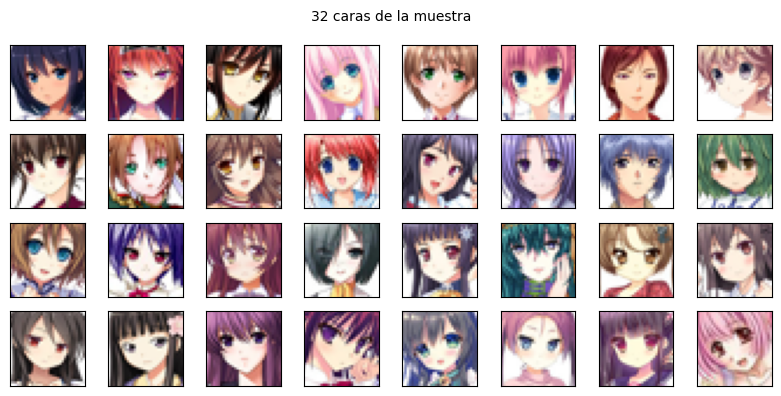

In [2]:
ZIP = ROOT / "data" / "animefaces" / "data.zip"
if not ZIP.exists():
    from huggingface_hub import hf_hub_download
    hf_hub_download("huggan/anime-faces", "data.zip", repo_type="dataset", local_dir=ZIP.parent)

N_MUESTRA, LADO = 12_000, 32
with zipfile.ZipFile(ZIP) as z:
    nombres = sorted(n for n in z.namelist() if n.endswith(".png"))
    elegidos = rng.choice(len(nombres), N_MUESTRA, replace=False)
    imgs = np.stack([
        np.asarray(Image.open(z.open(nombres[i])).convert("RGB").resize((LADO, LADO), Image.BICUBIC))
        for i in elegidos
    ])

X = torch.from_numpy(imgs).permute(0, 3, 1, 2).float() / 127.5 - 1
print("caras en el zip:", len(nombres))
print("forma del tensor:", tuple(X.shape), " rango:", float(X.min()), "a", float(X.max()))
rejilla(X[:32], 4, "32 caras de la muestra")

## 2. Etiquetas por color de cabello

El dataset no trae etiquetas, así que las fabricamos de forma automática: en estas caras la franja superior de la imagen es casi siempre cabello. Tomamos su color promedio y agrupamos las 12 000 caras en 4 grupos con k-medias. Las etiquetas son aproximadas, pero alcanzan para que la red aprenda a obedecer una condición.

grupo 0 (       oscuro):  3167 caras, color medio RGB=(100, 81, 89)
grupo 1 (azul o morado):  1631 caras, color medio RGB=(137, 133, 154)
grupo 2 (       rojizo):  2868 caras, color medio RGB=(191, 128, 114)
grupo 3 (        claro):  4334 caras, color medio RGB=(220, 193, 182)


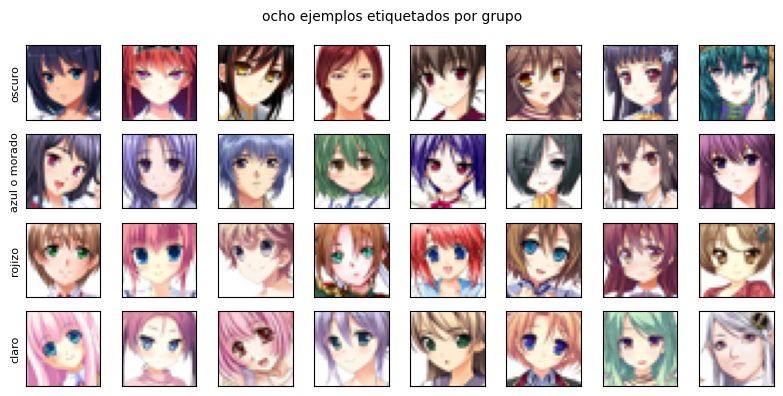

In [3]:
franja = X[:, :, :6, 8:24].mean(dim=(2, 3)).numpy()  # color medio de la franja superior (n, 3)

K = 4
centros = franja[rng.choice(len(franja), K, replace=False)]
for _ in range(50):
    Y = ((franja[:, None] - centros[None]) ** 2).sum(-1).argmin(1)
    centros = np.stack([franja[Y == k].mean(0) for k in range(K)])

# Ordenamos los grupos de oscuro a claro para que las etiquetas sean legibles
orden = np.argsort(centros.sum(1))
Y = np.argsort(orden)[Y]
centros = centros[orden]
# Nombres puestos a mano tras mirar los grupos (con la semilla 42 el agrupamiento es siempre el mismo)
NOMBRES = ["oscuro", "azul o morado", "rojizo", "claro"]
for k in range(K):
    r, g, b = ((centros[k] + 1) * 127.5).astype(int)
    print(f"grupo {k} ({NOMBRES[k]:>13}): {np.sum(Y == k):>5} caras, color medio RGB=({r}, {g}, {b})")

ejemplos = torch.cat([X[np.flatnonzero(Y == k)[:8]] for k in range(K)])
rejilla(ejemplos, K, "ocho ejemplos etiquetados por grupo", etiquetas_filas=NOMBRES)
Y = torch.from_numpy(Y)

## 3. Ruido sobre una cara

Igual que antes, solo que el horario es coseno y tiene $T=1000$ pasos, como en la sesión 07.

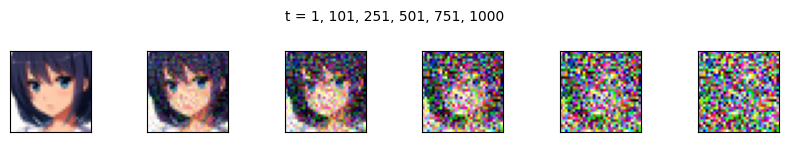

In [4]:
dif = td.Difusion(td.horario_coseno(td.T))
pasos = [0, 100, 250, 500, 750, 999]
x0 = X[:1].to(DEVICE)
eps = torch.randn_like(x0)
sucias = torch.cat([dif.q_sample(x0, torch.tensor([t], device=DEVICE), eps) for t in pasos]).cpu()
rejilla(sucias, 1, "t = " + ", ".join(str(t + 1) for t in pasos), lado=1.4)

## 4. La U-Net

La U-Net recibe la imagen ruidosa, el paso $t$ y la etiqueta, y devuelve el ruido estimado con la misma forma de la imagen.

- **Bajada:** dos reducciones convierten $32\times 32$ en $16\times 16$ y luego $8\times 8$, con más canales en cada nivel. Ahí la red ve la cara completa.
- **Centro:** una capa de atención en $8\times 8$ relaciona regiones lejanas, por ejemplo los dos ojos.
- **Subida:** vuelve a $32\times 32$. En cada nivel se pega lo que salió del mismo nivel en la bajada (las conexiones de salto). Así se conservan los bordes finos.
- **Condición:** el paso $t$ y la etiqueta se convierten en un vector que se suma dentro de cada bloque.

Durante el entrenamiento borramos la etiqueta el 15 % de las veces (la clase "nula"). Eso permite la guía sin clasificador al generar.

In [5]:
modelo = td.UNet(canales_img=3, n_clases=K).to(DEVICE)
ema = td.UNet(canales_img=3, n_clases=K).to(DEVICE)
ema.load_state_dict(modelo.state_dict())
ema.requires_grad_(False)
print(f"parámetros: {sum(p.numel() for p in modelo.parameters()):,}")

with torch.no_grad():
    prueba = modelo(X[:4].to(DEVICE), torch.tensor([0, 10, 500, 999], device=DEVICE), Y[:4].to(DEVICE))
print("entrada:", tuple(X[:4].shape), " salida:", tuple(prueba.shape))

parámetros: 2,927,043


entrada: (4, 3, 32, 32)  salida: (4, 3, 32, 32)


## 5. Entrenamiento

El ciclo de siempre: para cada lote, un $t$ y un ruido al azar, la U-Net predice el ruido y minimizamos el error cuadrático. Guardamos además una copia con promedio móvil de los pesos (EMA), que genera imágenes más limpias. Cada 5 épocas generamos 8 caras con el modelo a medio entrenar.

época  1/30  pérdida 0.6074  (6 s)


época  2/30  pérdida 0.1767  (12 s)


época  3/30  pérdida 0.1323  (18 s)


época  4/30  pérdida 0.1200  (24 s)


época  5/30  pérdida 0.1137  (30 s)


época  6/30  pérdida 0.1062  (42 s)


... (20 outputs left out)

época 27/30  pérdida 0.0862  (198 s)


época 28/30  pérdida 0.0851  (204 s)


época 29/30  pérdida 0.0866  (211 s)


época 30/30  pérdida 0.0866  (217 s)


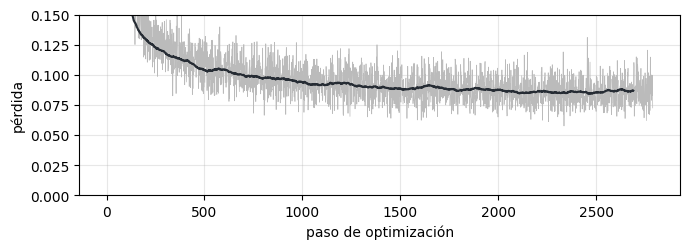

In [6]:
EPOCAS, LOTE, P_NULO = 30, 128, 0.15
opt = torch.optim.AdamW(modelo.parameters(), lr=2e-4)
pasos_total = EPOCAS * (len(X) // LOTE)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=4e-4, total_steps=pasos_total, pct_start=0.05)
gen = torch.Generator(device=DEVICE).manual_seed(SEED)
y_vista = torch.arange(K, device=DEVICE).repeat_interleave(2)
ruido_vista = torch.randn((8, 3, LADO, LADO), device=DEVICE, generator=gen)

perdidas, vistas = [], []
t0 = time.time()
for ep in range(1, EPOCAS + 1):
    perm = torch.randperm(len(X))
    for k in range(len(X) // LOTE):
        idx = perm[k * LOTE:(k + 1) * LOTE]
        x0, y = X[idx].to(DEVICE), Y[idx].to(DEVICE)
        y[torch.rand(len(y), device=DEVICE) < P_NULO] = K  # etiqueta nula
        t = torch.randint(0, dif.T, (len(x0),), device=DEVICE)
        eps = torch.randn_like(x0)
        with torch.autocast(device_type="cuda", dtype=torch.bfloat16):
            pred = modelo(dif.q_sample(x0, t, eps), t, y)
        perdida = F.mse_loss(pred.float(), eps)
        opt.zero_grad()
        perdida.backward()
        torch.nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
        opt.step()
        sched.step()
        with torch.no_grad():
            for pe, pm in zip(ema.parameters(), modelo.parameters()):
                pe.mul_(0.999).add_(pm, alpha=0.001)
        perdidas.append(perdida.item())
    print(f"época {ep:>2}/{EPOCAS}  pérdida {np.mean(perdidas[-(len(X) // LOTE):]):.4f}  ({time.time() - t0:.0f} s)")
    if ep % 5 == 0:
        ema.eval()
        x, _ = dif.muestrear(ema, ruido_vista.shape, set(), y=y_vista, guia=2.0, recortar=True, x_T=ruido_vista)
        vistas.append((ep, x.cpu()))

fig, ax = plt.subplots(figsize=(7, 2.6))
ax.plot(perdidas, color="#BBBBBB", lw=0.5)
ax.plot(np.convolve(perdidas, np.ones(100) / 100, mode="valid"), color="#262C34")
ax.set_xlabel("paso de optimización")
ax.set_ylabel("pérdida")
ax.set_ylim(0, 0.15)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Las mismas 8 semillas de ruido, generadas con el modelo cada 5 épocas (dos por grupo, en el orden oscuro, azul o morado, rojizo y claro). Se ve cómo pasa de manchas a caras.

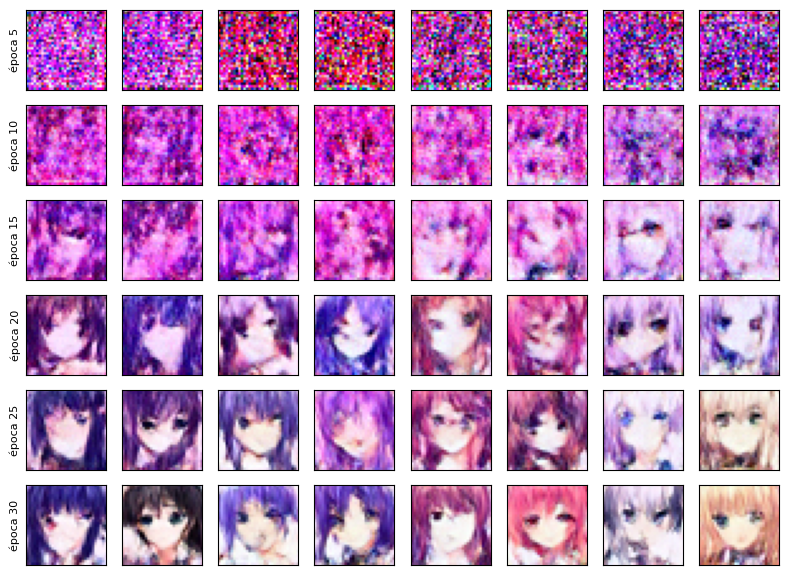

In [7]:
rejilla(torch.cat([v for _, v in vistas]), len(vistas), "", etiquetas_filas=[f"época {e}" for e, _ in vistas])

## 6. Inferencia paso a paso

Partimos de ruido puro y recorremos los 1000 pasos con el modelo EMA. Guardamos algunos momentos para ver cómo aparece la cara: primero la mancha de color y la silueta, al final los ojos y los bordes.

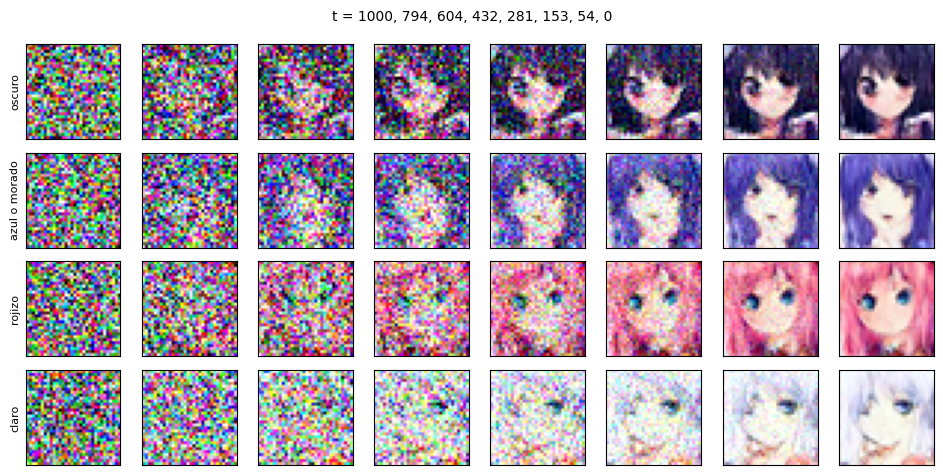

In [8]:
ema.eval()
momentos = td.instantes(8, 1.5)
gen = torch.Generator(device=DEVICE).manual_seed(7)
y_paso = torch.arange(K, device=DEVICE)
x, guardados = dif.muestrear(ema, (K, 3, LADO, LADO), set(momentos), y=y_paso, guia=2.0, recortar=True, gen=gen)

filas = torch.stack([guardados[m] for m in momentos], dim=1).reshape(-1, 3, LADO, LADO)
rejilla(filas, K, "t = " + ", ".join(str(m) for m in momentos), etiquetas_filas=NOMBRES, lado=1.2)

## 7. Generar por etiqueta

Ahora 8 caras nuevas por grupo. La guía sin clasificador combina la predicción con etiqueta y la predicción sin etiqueta:

$$\hat\epsilon=\hat\epsilon_{\text{nula}}+w\,(\hat\epsilon_{\text{etiqueta}}-\hat\epsilon_{\text{nula}}).$$

Con $w=1$ la red usa la etiqueta tal cual; con $w>1$ la obedece con más fuerza. Comparamos $w=1$ con $w=3$.

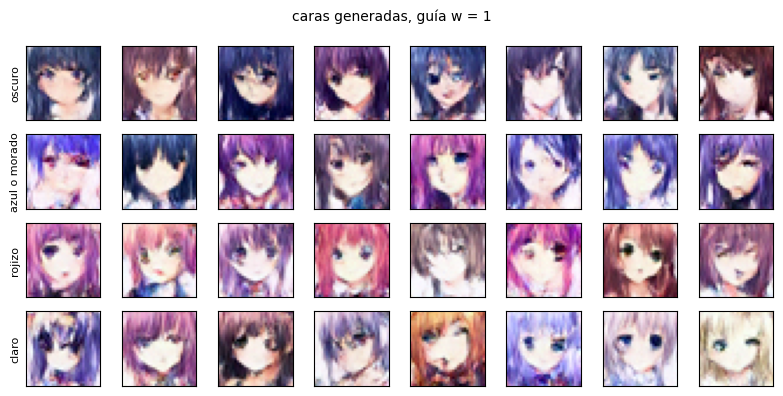

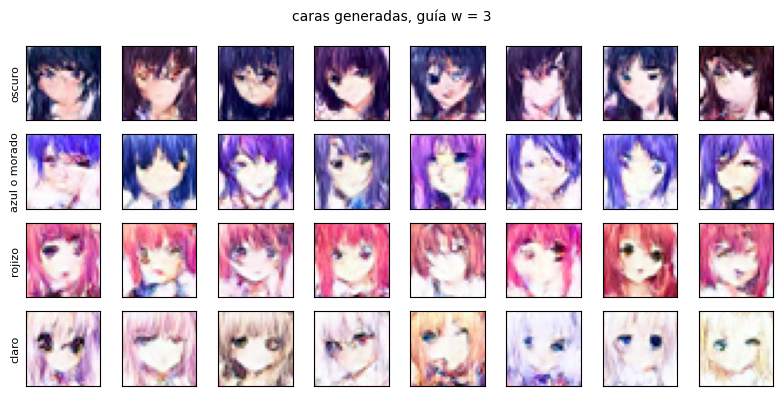

In [9]:
y_gen = torch.arange(K, device=DEVICE).repeat_interleave(8)
for w in [1.0, 3.0]:
    gen = torch.Generator(device=DEVICE).manual_seed(123)
    x, _ = dif.muestrear(ema, (len(y_gen), 3, LADO, LADO), set(), y=y_gen, guia=w, recortar=True, gen=gen)
    rejilla(x.cpu(), K, f"caras generadas, guía w = {w:g}", etiquetas_filas=NOMBRES)

## 8. ¿Copia o inventa?

Para cada cara generada buscamos la más parecida entre las 12 000 de entrenamiento. Si fueran iguales, la red estaría memorizando. Con 12 000 imágenes y 30 épocas lo normal es que se parezcan en estilo y colores sin ser la misma cara.

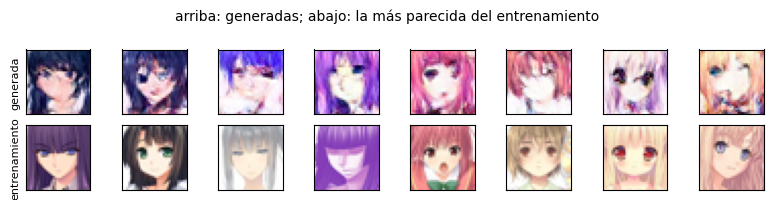

distancia media por píxel a la más cercana: [0.456 0.454 0.454 0.412 0.389 0.365 0.349 0.363]


In [10]:
gen_cpu = x[::4].cpu()
d = torch.cdist(gen_cpu.flatten(1), X.flatten(1))
cercanas = X[d.argmin(1)]
rejilla(torch.cat([gen_cpu, cercanas]), 2, "arriba: generadas; abajo: la más parecida del entrenamiento",
        etiquetas_filas=["generada", "entrenamiento"])
print("distancia media por píxel a la más cercana:", (d.min(1).values / gen_cpu[0].numel() ** 0.5).numpy().round(3))